# 27 · Granger por UF e tipologia

27 UFs × 2 períodos × 16 tipologias; 864 aplicações potenciais. BIC define defasagens 1 a 6 com intercepto e dummies mensais; F conjunto e BH dentro de UF × período. Não há identificação causal.

## 1. Entrada, integridade e objetivos

Os códigos desta revisão não substituem os arquivos originais; os dados consolidados devem ser fornecidos localmente. A inferência é exploratória.

In [1]:
import sys, os
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT/'src'))
SAIDA=ROOT/'outputs/tables/revisao_estadual_20261019'
assert SAIDA.exists()
print('Repositório:',ROOT)
print('Base:',os.getenv('TCC_BASE_CSV',str(ROOT/'data/processed/df_tcc_2013_2024.csv')))


Repositório: /mnt/data/tcc_revisao/repo
Base: /mnt/data/tcc_bases/df_tcc_2013_2024_recovered.csv


## 2. Especificação e testes

`y_t=c+Σ ρ_j y_{t-j}+Σ γ_j x_{t-j}+dummies_mês+ε_t`, com `y=Δlog(I)` e `x=Δlog(1+D)`. H₀: γ₁=…=γₚ=0. O teste F clássico requer diagnóstico residual adequado. Defasagens selecionadas por BIC, nunca por menor p.

In [2]:
from analise_estadual import load, granger
resultado=granger(load())
print("planejados",len(resultado),"estimados",int((resultado.status=="estimado").sum()),"BH",int(resultado.rejeicao_bh.sum()))
display(resultado.status.value_counts().to_frame("n"))

planejados 864 estimados 627 BH 14


,n
status,
estimado,627
exposição transformada constante,227
sem modelo de posto completo na grade,10


## 3. Rejeições ajustadas e diagnóstico

In [3]:
rejeicoes=resultado[resultado.rejeicao_bh].sort_values(["periodo","uf","q_bh"])
display(rejeicoes[["uf","periodo","tipologia","p_lags","p","q_bh","ljungbox_p"]])
print("rejeições BH com LB12 favorável:",int((rejeicoes.ljungbox_p>=.05).sum()))

,uf,periodo,tipologia,p_lags,p,q_bh,ljungbox_p
16,AL,Pré,tipo_alagamentos,1.0,7.469455e-03,3.983709e-02,0.274391
19,AL,Pré,tipo_enxurradas,1.0,7.469455e-03,3.983709e-02,0.274391
24,AL,Pré,tipo_inundacoes,1.0,7.469455e-03,3.983709e-02,0.274391
17,AL,Pré,tipo_chuvas_intensas,1.0,1.135188e-02,4.540753e-02,0.310762
161,MG,Pré,tipo_chuvas_intensas,3.0,3.700429e-04,5.920687e-03,0.802680
194,MT,Pré,tipo_doencas_infecciosas,3.0,1.059986e-03,1.695977e-02,0.727862
208,PA,Pré,tipo_alagamentos,2.0,1.273501e-03,2.037601e-02,0.681278
243,PE,Pré,tipo_enxurradas,1.0,6.860359e-04,1.097658e-02,0.326433
268,PI,Pré,tipo_outros,4.0,2.925606e-04,4.680970e-03,0.393329
305,RN,Pré,tipo_chuvas_intensas,4.0,1.280114e-04,2.048182e-03,0.775986


rejeições BH com LB12 favorável: 12


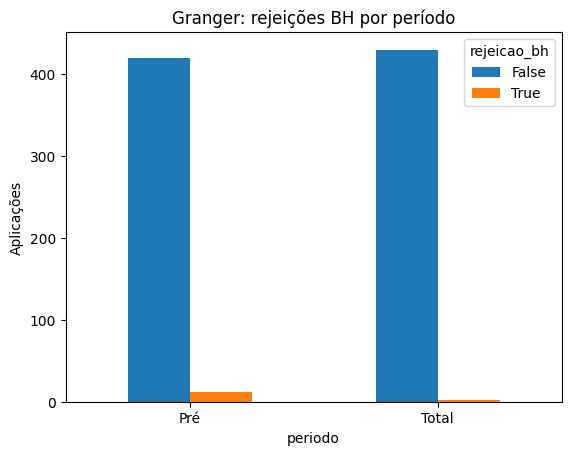

In [4]:
pd.crosstab(resultado.periodo,resultado.rejeicao_bh).plot(kind="bar",rot=0,title="Granger: rejeições BH por período");plt.ylabel("Aplicações");plt.show()

## 4. Interpretação

Rejeições são sinais de precedência preditiva condicional, não impacto causal. Os resultados pré-pandemia e os casos com autocorrelação residual exigem ressalvas. Não estimáveis mantêm status distinto de não rejeição.